**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**07 | Expanded Subject-Level Development Evaluation**

![Stage 07 scientific workflow](../images/07_workflow.svg)

**Objective:** Extend participant-disjoint Development cross-validation from six to ten HARTH participants and assess activity coverage and model variability.

**Dataset:** Ten HARTH v2.0 Development recordings, comprising the six earlier participants plus S029, S030, S031 and S033.

**Notebook Scope:** Audit documented activity codes and run five Development folds. Reserved Test participants S023 and S032 are not loaded, and no independent final Test evaluation is performed.

**01. Imports and Reusable Python Utilities**

In [1]:
# ======================== 01. Imports and Environment ========================

# ------------ 1. Import standard-library tools for project paths. ------------
import sys
from pathlib import Path

# --------------- 2. Import NumPy and pandas for source tables. ---------------
import numpy as np
import pandas as pd

# ------------ 3. Import plotting and notebook display utilities. -------------
import matplotlib.pyplot as plt
from IPython.display import display

# --------- 4. Resolve the repository root without local drive paths. ---------
root = Path.cwd().resolve()
while not (root / "code/python/src/core/data_loading.py").is_file():
    if root == root.parent:
        raise RuntimeError("Run from within the human-movement-intelligence repository.")
    root = root.parent

# ---------- 5. Register shared and HARTH Python module directories. ----------
sys.path.insert(0, str(root / "code/python/src"))
sys.path.insert(0, str(root / "studies/wearable_activity_recognition/src"))

# --------- 6. Import the existing feature cohort and group-CV tools. ---------
from harth_data import ACTIVITY_NAMES, prepare_harth_feature_cohort
from core.group_cross_validation import evaluate_group_cross_validation

# --------------- 7. Confirm research utilities are available. ----------------
print("Shared research components: ready")

Shared research components: ready


**02. Expand Development while Reserving Original Test**

Reuse the six Development recordings from Notebook 06 and add S029, S030, S031 and S033. S023 and S032 remain outside data loading and cross-validation.

In [2]:
# ================= 02. Prepare Ten Development Participants ==================

# ------------- 1. Keep the original final Test people excluded. --------------
RESERVED_TEST = {"S023", "S032"}

# ----------- 2. Define six existing and four additional subjects. ------------
DEVELOPMENT_SUBJECTS = [
    "S024", "S025", "S027", "S028", "S034", "S035",
    "S029", "S030", "S031", "S033",
]

# --------------- 3. Preserve the documented eight-class task. ----------------
TASK_CLASSES = tuple(range(1, 9))

# ----------- 4. Check the ten Development identifiers are unique. ------------
assert len(DEVELOPMENT_SUBJECTS) == len(set(DEVELOPMENT_SUBJECTS)) == 10

# ------------- 5. Check disjoint Development and Test subjects. --------------
assert not (set(DEVELOPMENT_SUBJECTS) & RESERVED_TEST)

# ---------- 6. Build time-safe windows and thirty-feature vectors. -----------
features, metadata, overview, excluded = prepare_harth_feature_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES,
    window_size=100, step_size=50, sampling_rate=50,
)

# ------------- 7. Display real participant and window coverage. --------------
display(overview)

# ------------- 8. Report the expanded Development matrix shape. --------------
print("Expanded development matrix:", features.shape)

# --------- 9. Confirm the original Test recordings were not loaded. ----------
print("Original final Test participants loaded: NO")

Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S024.csv
HARTH subject S024: 170,534 rows, 6 sensors
Input signal: 170,534 samples, 6 channels
Candidate windows: 3,409
Retained windows: 3,119 | Shape: (3119, 6, 100)
Rejected candidates: 290
Input windows: (3119, 6, 100)
Feature matrix: (3119, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S025.csv
HARTH subject S025: 231,729 rows, 6 sensors
Input signal: 231,729 samples, 6 channels
Candidate windows: 4,633
Retained windows: 4,272 | Shape: (4272, 6, 100)
Rejected candidates: 361
Input windows: (4272, 6, 100)
Feature matrix: (4272, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S027.csv
HARTH subject S027: 158,584 rows, 6 sensors
Input signal: 158,584 samples, 6 channels
Candidate windows: 3,170
Retained windows: 3,082 | Shape: (3082, 6, 1

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:203: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Input windows: (3335, 6, 100)
Feature matrix: (3335, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S031.csv


D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:203: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Input windows: (4411, 6, 100)
Feature matrix: (4411, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Input windows: (3687, 6, 100)
Feature matrix: (3687, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Eligible dataset: 10 subjects, 31,903 windows, 30 features


,subject_id,raw_samples,retained_windows,eligible_windows,excluded_windows,undocumented_raw_rows,task_classes_present
0,S024,170534,3119,3119,0,0,8
1,S025,231729,4272,2873,1399,0,8
2,S027,158584,3082,3082,0,0,6
3,S028,165178,3197,3197,0,0,7
4,S034,188202,3351,3351,0,0,7
5,S035,181251,3337,3337,0,0,5
6,S029,178716,3371,3147,224,0,8
7,S030,245994,3335,3312,23,4512,6
8,S031,269560,4411,2798,1613,334,6
9,S033,201688,3687,3687,0,0,6


Expanded development matrix: (31903, 30)
Original final Test participants loaded: NO


**03. Audit Source Codes and Class Coverage**

Retain documented activity codes 1–8 after time-safe windowing. Count excluded codes and inspect class availability by participant without assigning meanings to undocumented labels.

In [3]:
# =============== 03. Review Source Label and Activity Support ================

# -------------- 1. Introduce the excluded original label audit. --------------
print("Excluded windows by original source code:")

# ---------- 2. Display exclusions without relabelling source codes. ----------
display(excluded.sort_values(["source_code", "subject_id"]))

# ------------ 3. Count eligible activity windows by participant. -------------
class_coverage = pd.crosstab(
    metadata["subject_id"], metadata["label"]
).reindex(index=DEVELOPMENT_SUBJECTS, columns=TASK_CLASSES, fill_value=0)

# ------------ 4. Attach documented activity labels to the table. -------------
class_coverage.columns = [
    f"{code}: {ACTIVITY_NAMES[code]}" for code in TASK_CLASSES
]

# ------------- 5. Show the participant-by-class coverage matrix. -------------
display(class_coverage)

# ------------- 6. Summarise class availability for each subject. -------------
print("Classes present per subject:", (class_coverage > 0).sum(axis=1).to_dict())

# ------------- 7. Report participant support for each activity. --------------
print("Subjects per class:", (class_coverage > 0).sum(axis=0).to_dict())

Excluded windows by original source code:


,subject_id,source_code,source_activity,excluded_windows
6,S030,11,UNDOCUMENTED source code,15
0,S025,13,Cycling seated,1018
4,S029,13,Cycling seated,199
8,S031,13,Cycling seated,1613
1,S025,14,Cycling standing,238
7,S030,17,UNDOCUMENTED source code,8
2,S025,130,Cycling seated inactive,78
5,S029,130,Cycling seated inactive,25
3,S025,140,Cycling standing inactive,65


,1: Walking,2: Running,3: Shuffling,4: Stairs ascending,5: Stairs descending,6: Standing,7: Sitting,8: Lying
subject_id,,,,,,,,
S024,1492,511,7,48,38,134,274,615
S025,1241,675,63,62,35,227,167,403
S027,35,2608,11,0,0,16,192,220
S028,2939,0,8,14,19,135,51,31
S034,517,0,51,34,27,1085,1273,364
S035,1838,0,9,0,0,322,629,539
S029,2384,351,56,6,12,177,66,95
S030,788,0,93,65,46,2238,82,0
S031,915,0,30,60,87,765,941,0


Classes present per subject: {'S024': 8, 'S025': 8, 'S027': 6, 'S028': 7, 'S034': 7, 'S035': 5, 'S029': 8, 'S030': 6, 'S031': 6, 'S033': 6}
Subjects per class: {'1: Walking': 10, '2: Running': 5, '3: Shuffling': 10, '4: Stairs ascending': 7, '5: Stairs descending': 7, '6: Standing': 10, '7: Sitting': 10, '8: Lying': 8}


**04. Visualise Ten-Person Activity Support**

Use a participant-by-activity count heatmap to show which classes occur in the Development cohort. The plot describes data support, not prediction accuracy.

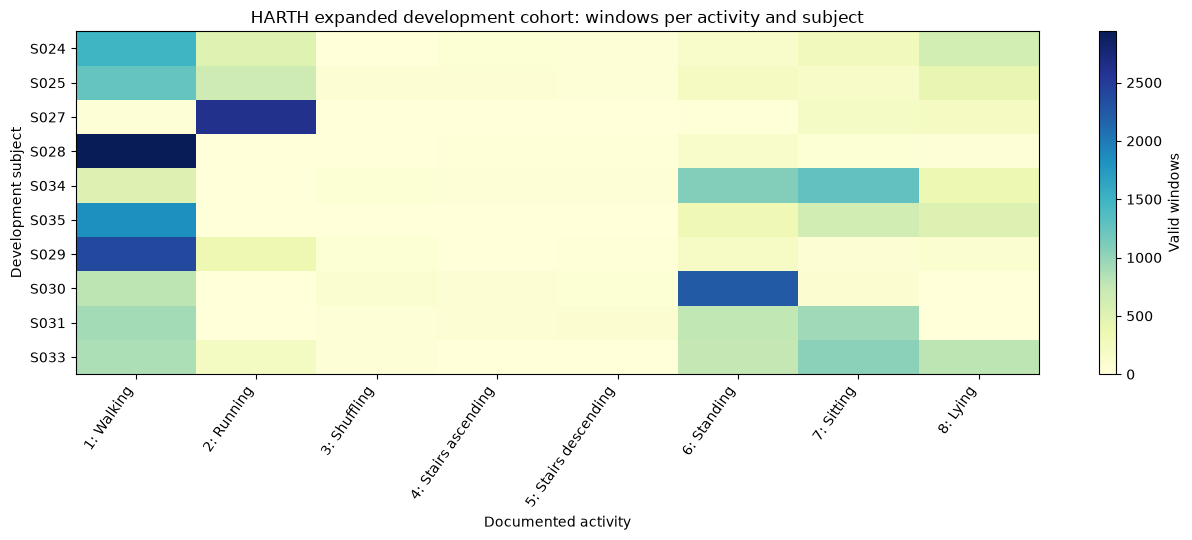

In [4]:
# ================ 04. Visualise Participant Activity Coverage ================

# ----------- 1. Initialise the observed activity-coverage figure. ------------
fig, ax = plt.subplots(figsize=(13, 5.5))

# ------------- 2. Render true per-person activity-window counts. -------------
heat = ax.imshow(class_coverage.to_numpy(), aspect="auto", cmap="YlGnBu")

# ----------------- 3. Label all documented activity columns. -----------------
ax.set_xticks(np.arange(len(class_coverage.columns)), class_coverage.columns, rotation=55, ha="right")

# ---------------- 4. Label all ten Development participants. -----------------
ax.set_yticks(np.arange(len(class_coverage.index)), class_coverage.index)

# ------------- 5. State that this heatmap reports class support. -------------
ax.set(title="HARTH expanded development cohort: windows per activity and subject",
       xlabel="Documented activity", ylabel="Development subject")

# ----------- 6. Add the original valid-window count colour scale. ------------
fig.colorbar(heat, ax=ax, label="Valid windows")

# ---------------- 7. Align heatmap and labels for legibility. ----------------
fig.tight_layout()

# ------------- 8. Display the saved participant coverage figure. -------------
plt.show()

**05. Run Five Subject-Disjoint Development Folds**

Each fold holds out two participants and trains on the other eight. Refit the classifiers and Train-only Logistic Regression scaler within each fold; reject folds without adequate training-class coverage.

In [5]:
# ============== 05. Evaluate Five Participant-Disjoint CV Folds ==============

# ---------- 1. Fit three baseline models in five Development folds. ----------
fold_results, subject_results, summary = evaluate_group_cross_validation(
    features=features.to_numpy(),
    labels=metadata["label"].to_numpy(),
    group_ids=metadata["subject_id"].to_numpy(),
    classes=TASK_CLASSES,
    n_splits=5,
    random_state=42,
)

# ---------------- 2. Display cross-fold validation summaries. ----------------
display(summary.round(4))

# ------------ 3. Inspect fold membership and validation metrics. -------------
display(fold_results[[
    "fold", "model", "train_subjects", "validation_subjects",
    "validation_classes_present", "macro_f1", "balanced_accuracy"
]].round(4))

Fold 1: Train=8 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.0539
Logistic Regression: Validation Macro F1 = 0.6451
Random Forest: Validation Macro F1 = 0.7892
Fold 2: Train=8 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.0551
Logistic Regression: Validation Macro F1 = 0.8370
Random Forest: Validation Macro F1 = 0.6599
Fold 3: Train=8 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.0565


c:\Users\Reza\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Logistic Regression: Validation Macro F1 = 0.6351
Random Forest: Validation Macro F1 = 0.7031
Fold 4: Train=8 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.0654
Logistic Regression: Validation Macro F1 = 0.7139
Random Forest: Validation Macro F1 = 0.7350
Fold 5: Train=8 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.1141
Logistic Regression: Validation Macro F1 = 0.7630
Random Forest: Validation Macro F1 = 0.7302


,model,fold_macro_f1_mean,fold_macro_f1_sd,fold_macro_f1_min,fold_macro_f1_max,subject_macro_f1_fixed_mean,subject_macro_f1_observed_mean
0,Random Forest,0.7235,0.0473,0.6599,0.7892,0.6110,0.7394
1,Logistic Regression,0.7188,0.0843,0.6351,0.8370,0.6133,0.7281
2,Dummy (most frequent),0.0690,0.0256,0.0539,0.1141,0.0666,0.0795


,fold,model,train_subjects,validation_subjects,validation_classes_present,macro_f1,balanced_accuracy
0,1,Random Forest,"S024, S025, S027, S028, S029, S030, S034, S035","S031, S033",8,0.7892,0.9123
1,1,Logistic Regression,"S024, S025, S027, S028, S029, S030, S034, S035","S031, S033",8,0.6451,0.8210
2,1,Dummy (most frequent),"S024, S025, S027, S028, S029, S030, S034, S035","S031, S033",8,0.0539,0.1250
3,2,Logistic Regression,"S024, S027, S028, S029, S030, S031, S033, S035","S025, S034",8,0.8370,0.8656
4,2,Random Forest,"S024, S027, S028, S029, S030, S031, S033, S035","S025, S034",8,0.6599,0.6513
5,2,Dummy (most frequent),"S024, S027, S028, S029, S030, S031, S033, S035","S025, S034",8,0.0551,0.1250
6,3,Random Forest,"S024, S025, S028, S029, S030, S031, S033, S034","S027, S035",6,0.7031,0.9705
7,3,Logistic Regression,"S024, S025, S028, S029, S030, S031, S033, S034","S027, S035",6,0.6351,0.9549
8,3,Dummy (most frequent),"S024, S025, S028, S029, S030, S031, S033, S034","S027, S035",6,0.0565,0.1667
9,4,Random Forest,"S025, S027, S028, S029, S031, S033, S034, S035","S024, S030",8,0.7350,0.6999


**06. Compare Fold and Participant Model Stability**

Inspect fixed-task Macro F1 by fold and by held-out participant, since aggregate means can hide differences between people.

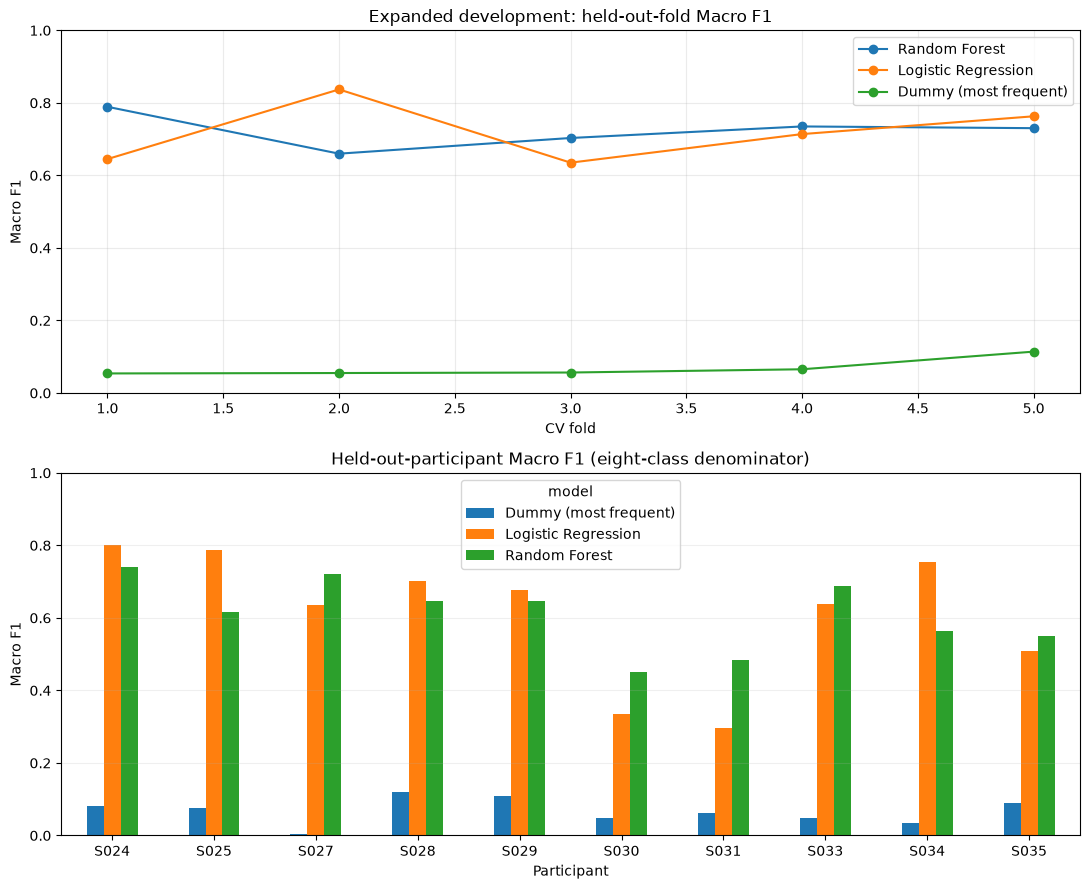

,fold,model,subject_id,windows,observed_classes,macro_f1_fixed_task,macro_f1_observed_classes
18,4,Dummy (most frequent),S024,3119,8,0.0809,0.0809
6,2,Dummy (most frequent),S025,2873,8,0.0754,0.0754
12,3,Dummy (most frequent),S027,3082,6,0.0028,0.0037
24,5,Dummy (most frequent),S028,3197,7,0.1197,0.1369
25,5,Dummy (most frequent),S029,3147,8,0.1078,0.1078
19,4,Dummy (most frequent),S030,3312,6,0.0480,0.0641
0,1,Dummy (most frequent),S031,2798,6,0.0616,0.0821
1,1,Dummy (most frequent),S033,3687,6,0.0477,0.0636
7,2,Dummy (most frequent),S034,3351,7,0.0334,0.0382
13,3,Dummy (most frequent),S035,3337,5,0.0888,0.1421


In [ ]:
# ================ 06. Compare Fold and Subject-Level Results =================

# ------------ 1. Set up the original two-panel evaluation figure. ------------
fig, axes = plt.subplots(2, 1, figsize=(11, 9))

# ------------ 2. Compare Macro F1 across the five held-out folds. ------------
for name, part in fold_results.groupby("model", sort=False):
    part = part.sort_values("fold")
    axes[0].plot(part["fold"], part["macro_f1"], marker="o", label=name)

axes[0].set(title="Expanded development: held-out-fold Macro F1",
            xlabel="CV fold", ylabel="Macro F1", ylim=(0, 1))
axes[0].grid(alpha=0.25)
axes[0].legend()

# --------------- 3. Align fixed-task Macro F1 by participant. ----------------
per_subject = subject_results.pivot(
    index="subject_id", columns="model", values="macro_f1_fixed_task"
).sort_index()

# -------------- 4. Plot observed per-person validation scores. ---------------
per_subject.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set(title="Held-out-participant Macro F1 (eight-class denominator)",
            xlabel="Participant", ylabel="Macro F1", ylim=(0, 1))
axes[1].grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

# ------------- 5. Display participant-level validation results. --------------
display(subject_results.sort_values(["model", "subject_id"]).round(4))

**07. Research Quality Gate and Evidence Limitations**

Confirm ten-participant coverage, group separation and Test exclusion. These exploratory Development results precede the frozen 29-person protocol and do not establish external generalisation.


In [7]:
# =================== 07. Expanded Development Quality Gate ===================

# ------------- 1. Collect the participant IDs in the CV results. -------------
reported_subjects = set(subject_results["subject_id"])

# ---------- 2. Confirm all ten Development people are represented. -----------
assert reported_subjects == set(DEVELOPMENT_SUBJECTS)

# ----------- 3. Assert no original Test participant was evaluated. -----------
assert not (reported_subjects & RESERVED_TEST)

# -------------- 4. Check each subject-model summary is unique. ---------------
assert subject_results.groupby(["model", "subject_id"]).size().eq(1).all()

# ------------- 5. Check that all fold Macro F1 scores are valid. -------------
assert fold_results["macro_f1"].between(0, 1).all()

# ------------ 6. Check fifteen model-by-fold evaluation results. -------------
assert len(fold_results) == 5 * 3

# --------------- 7. Verify finite Development feature values. ----------------
assert np.isfinite(features.to_numpy()).all()

# ---------- 8. Report the original passed scientific quality gate. -----------
print("Expanded development grouped CV: PASSED")

# ------------- 9. Explicitly confirm no Test access or scoring. --------------
print("Original final Test data loaded/evaluated: NO")

# ----------- 10. State the limitations on clinical generalisation. -----------
print("Clinical/generalisation claim: NOT SUPPORTED")

Expanded development grouped CV: PASSED
Original final Test data loaded/evaluated: NO
Clinical/generalisation claim: NOT SUPPORTED
